In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import gzip
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)


In [49]:
##load single cells (ProM & G1)

In [2]:
#load single cell profile of all G1 and proM
path = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_0115_2023/results_12merge/pairs_library/"

conditions_1 = []
samplecolor = OrderedDict()
col = '#487e71'
for i in range(0,96):
    if (i == 48):
        col = '#ed4141'
    conditions_t = "scHiC_cell_0115_" + str(i+1)
    conditions_1.append(conditions_t)
    samplecolor[conditions_t] = col

os.chdir(path)
os.getcwd()

#get the .pair table
pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

dfs = {}
Num_Contacts = {}
for cond in conditions_1:
    with gzip.open(cond + ".hg38.nodups.pairs.gz", 'rt') as file:
        df = pd.read_csv(file, sep="\t", header=None, comment="#", names=pairs_header, index_col=None)
    
    Num_Cont = len(df)
    Num_Contacts[cond] = Num_Cont
    df = df[df["pair_type"] == "UU"]
    
    dfs[cond] = {'df': df}

In [3]:
#get the second batch
path = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_1203_2022/1+2_sc_results/pairs_library"

conditions_2 = []
samplecolor = OrderedDict()
col = '#487e71'
for i in range(0,96):
    if (i == 48):
        col = '#ed4141'
    conditions_t = "scHiC_cell" + str(i+1)
    conditions_2.append(conditions_t)
    samplecolor[conditions_t] = col

os.chdir(path)
os.getcwd()

for cond in conditions_2:
    with gzip.open(cond + ".hg38.nodups.pairs.gz", 'rt') as file:
        df = pd.read_csv(file, sep="\t", header=None, comment="#", names=pairs_header, index_col=None)
    
    Num_Cont = len(df)
    Num_Contacts[cond] = Num_Cont
    df = df[df["pair_type"] == "UU"]
    
    dfs[cond] = {'df': df}

In [4]:
#load compartment profile

In [5]:
#get compartment files
compartment = pd.read_csv("/home/xiangru.huo-umw/scHiC/benchmark/plot_files/cooler_data/G1_merge.250kb.2combo.mapq30.byarm.eigs.cis.vecs.E1.bedGraph",
        sep="\t",
        header=None,
        comment="#",index_col=None)
compartment.columns = ['chrom', 'start', 'end', 'E1']

In [6]:
compartment

,chrom,start,end,E1
0,chr1,0,250000,NaN
1,chr1,250000,500000,NaN
2,chr1,500000,750000,NaN
3,chr1,750000,1000000,1.499379
4,chr1,1000000,1250000,0.651695
...,...,...,...,...
12362,chrY,56250000,56500000,NaN
12363,chrY,56500000,56750000,NaN
12364,chrY,56750000,57000000,-0.390821
12365,chrY,57000000,57227415,NaN


In [7]:
chrom_size = {
    'chr1': '248956422',    'chr2': '242193529',
    'chr3': '198295559',    'chr4': '190214555',
    'chr5': '181538259',    'chr6': '170805979',
    'chr7': '159345973',    'chr8': '145138636',
    'chr9': '138394717',    'chr10': '133797422',
    'chr11': '135086622',    'chr12': '133275309',
    'chr13': '114364328',    'chr14': '107043718',
    'chr15': '101991189',    'chr16': '90338345',
    'chr17': '83257441',    'chr18': '80373285',
    'chr19': '58617616',    'chr20': '64444167',
    'chr21': '46709983',    'chr22': '50818468',
    'chrX': '156040895',    'chrY': '57227415'}

chrom_size_df = pd.DataFrame(list(chrom_size.items()), columns=['chrom', 'Size'])
# Convert the 'Size' column to integer type
chrom_size_df['Size'] = chrom_size_df ['Size'].astype(int)

In [8]:
#identify unique_chrom_value
unique_chrom = compartment['chrom'].unique()
#remove chrM from unique_chrom
unique_chrom_nuclei = unique_chrom[:-1]

In [9]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [10]:
#apply "split_df_by_chrom" function 
comp_split = split_df_by_chrom(compartment)

In [11]:
#define a bin combine function (1M = 4, 2M = 8)
def create_continuous_ranges(df, Mg):
    original_list = df.index 
    # Split the indices into lists of length Mg
    index_lists = [original_list[i:i+Mg] for i in range(0, len(original_list), Mg)]

    df_Mg = pd.DataFrame(columns=["chrom", "start", "end", "E1"])
    
    # Loop through the index_lists
    for indices in index_lists:
        start_index = indices[0]
        end_index = indices[-1]       
        # Create a temporary DataFrame for the current continuous range
        df_continues_tmp = pd.DataFrame({
            "chrom": [df['chrom'][start_index]],
            "start": [df['start'][start_index]],
            "end": [df['end'][end_index]],
            "E1": [df['E1'][start_index:end_index].mean()]
        })        
        # Concatenate the temporary DataFrame to the main DataFrame
        df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
        df_Mg['start'] = df_Mg['start'].astype(int)
        df_Mg['end'] = df_Mg['end'].astype(int)
        df_Mg['E1'] = df_Mg['E1'].astype(float)
    
    # Add a Bin_ID column to the DataFrame
    df_Mg["Bin_ID"] = df_Mg["chrom"] + "_Bin" + df_Mg.index.astype(str)
    
    return df_Mg

In [12]:
#apply "create_continuous_ranges" function on comp_split
comp_chrom_bin = {}
for chrom in unique_chrom_nuclei:
    comp_chrom_bin[chrom] = create_continuous_ranges(comp_split[chrom], 4)

In [13]:
#get comp bin table
comp_bin = pd.concat(comp_chrom_bin.values(), ignore_index=True)

In [14]:
bf.is_bedframe(comp_bin)

True

In [15]:
#load the interphase/proM info
ShortVSMitotic = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_ShortVSMitotic.csv", index_col=0)
#Selecte cells contacts > 20K 
Cell_20K = ShortVSMitotic[ShortVSMitotic['Num_Contacts'] > 20000]
Cell_20K

,Short_ratio(1.5K-2Mb),Mitotic_ratio(2Mb-12Mb),type,type2,Num_Contacts
scHiC_cell_0115_1,0.663677,0.132735,G1,G1,28790.0
scHiC_cell_0115_3,0.767010,0.095361,G1,G1,79862.0
scHiC_cell_0115_4,0.643443,0.155738,G1,G1,28002.0
scHiC_cell_0115_5,0.865278,0.059040,G1,G1,365748.0
scHiC_cell_0115_6,0.667149,0.143994,G1,G1,20342.0
...,...,...,...,...,...
scHiC_cell91,0.873054,0.071747,proM,proM_G1,41825.0
scHiC_cell92,0.852878,0.077861,proM,proM_G1,239150.0
scHiC_cell93,0.619937,0.290009,proM,proM_proM,381866.0
scHiC_cell94,0.563764,0.315631,proM,proM_proM,106048.0


In [16]:
# Initialize the reorganized contacts dictionary
contacts_reorganized = {}

# Get the conditions from the column names
condition = Cell_20K.index  # Ensure this is correctly retrieving columns

for cond in condition:
    # Copy the DataFrame for each condition
    df = dfs[cond]['df'].copy()
    
    #contacts_reorganized[stage][plate][cond] = df
    #filter the contacts in cells > 0.3kb or others
    df_filtered = df[(df['chrom1'] != df['chrom2']) | 
                     ((df['chrom1'] == df['chrom2']) & (df['pos2'] - df['pos1'] > 300))]

    # Assign the filtered DataFrame to the reorganized dictionary
    contacts_reorganized[cond] = df_filtered

In [17]:
#generate bin id to each contacts per cell
def generate_contacts_bin_id(df):
    # Process 'chrom1' and 'pos1'
    df1 = df[['chrom1', 'pos1']].copy()
    df1.rename(columns={'chrom1': 'chrom', 'pos1': 'start'}, inplace=True)
    df1['end'] = df1['start'] + 1
    df1_binID = bf.overlap(df1, comp_bin, how='left', suffixes=('_1', '_2'))
    df1_binID = df1_binID.loc[:, ['chrom_1', 'start_1', 'Bin_ID_2']].copy()
    df1_binID.columns = ['chrom1', 'pos1', 'Bin_ID_1']

    # Process 'chrom2' and 'pos2'
    df2 = df[['chrom2', 'pos2']].copy()
    df2.rename(columns={'chrom2': 'chrom', 'pos2': 'start'}, inplace=True)
    df2['end'] = df2['start'] + 1
    df2_binID = bf.overlap(df2, comp_bin, how='left', suffixes=('_1', '_2'))
    df2_binID = df2_binID.loc[:, ['chrom_1', 'start_1', 'Bin_ID_2']].copy()
    df2_binID.columns = ['chrom2', 'pos2', 'Bin_ID_2']

    # Concatenate the results
    df_binID = pd.concat([df1_binID, df2_binID], axis=1)

    return df_binID

In [18]:
# Call the function "generate_contacts_Bin_id" and store the result
contacts_Bin_ID = {}

for cond in condition:
    df = contacts_reorganized[cond].copy()
    contacts_Bin_ID[cond] = generate_contacts_bin_id(df)

In [19]:
contacts_Bin_ID['scHiC_cell_0115_4']

,chrom1,pos1,Bin_ID_1,chrom2,pos2,Bin_ID_2
0,chr1,10119,chr1_Bin0,chr1,248946072,chr1_Bin248
1,chr1,1441335,chr1_Bin1,chr1,1441845,chr1_Bin1
2,chr1,1441335,chr1_Bin1,chr1,1441913,chr1_Bin1
3,chr1,1441335,chr1_Bin1,chr1,1442069,chr1_Bin1
4,chr1,1441416,chr1_Bin1,chr1,1442434,chr1_Bin1
...,...,...,...,...,...,...
11965,chrX,155690880,chrX_Bin155,chrX,155691206,chrX_Bin155
11966,chrX,155690880,chrX_Bin155,chrX,155691208,chrX_Bin155
11967,chrX,155722285,chrX_Bin155,chrX,155722729,chrX_Bin155
11968,chrX,90725096,chrX_Bin90,chrY,4306878,chrY_Bin4


In [68]:
#count the cis/total ratio

In [20]:
#define the function to get the cis_ratio per cell
def calculate_cis_ratio(df):
    # Get cis_count and total_count from pos1
    cis_count = pd.DataFrame(df.groupby('Bin_ID_1')['chrom2'].apply(lambda x: x.value_counts().max()).reset_index())
    total_count = pd.DataFrame(df.groupby('Bin_ID_1')['chrom2'].apply(lambda x: x.value_counts().sum()).reset_index())
    cis_ratio = pd.merge(cis_count, total_count, on='Bin_ID_1', how='outer')
    cis_ratio.columns = ['Bin_ID_1', 'cis_count1', 'total_count1']
    cis_ratio['trans_count1'] = cis_ratio['total_count1'] - cis_ratio['cis_count1']

    # Get cis_count and total_count from pos2
    cis_count2 = pd.DataFrame(df.groupby('Bin_ID_2')['chrom1'].apply(lambda x: x.value_counts().max()).reset_index())
    total_count2 = pd.DataFrame(df.groupby('Bin_ID_2')['chrom1'].apply(lambda x: x.value_counts().sum()).reset_index())
    cis_ratio2 = pd.merge(cis_count2, total_count2, on='Bin_ID_2', how='outer')
    cis_ratio2.columns = ['Bin_ID_1', 'cis_count_2', 'total_count_2']
    cis_ratio2['trans_count2'] = cis_ratio2['total_count_2'] - cis_ratio2['cis_count_2']

    # Combine them together
    cis_ratio_all = pd.merge(cis_ratio, cis_ratio2, on='Bin_ID_1', how='outer')
    cis_ratio_all['cis_count_final'] = cis_ratio_all[['cis_count1', 'cis_count_2']].max(axis=1)
    cis_ratio_all['trans_count_final'] = cis_ratio_all['trans_count1'] + cis_ratio_all['trans_count2']
    cis_ratio_all['total_count_final'] = cis_ratio_all['cis_count_final'] + cis_ratio_all['trans_count_final']
    cis_ratio_all['cis_ratio_final'] = cis_ratio_all['cis_count_final'] / cis_ratio_all['total_count_final']

    return cis_ratio_all

In [21]:
# Call the function "calculate_cis_ratio" and store the result
cis_ratio_Bin_ID = {}

for cond in condition:
        df = contacts_Bin_ID[cond].copy()
        cis_ratio_Bin_ID[cond] = calculate_cis_ratio(df)

In [22]:
cis_ratio_Bin_ID[cond]

,Bin_ID_1,cis_count1,total_count1,trans_count1,cis_count_2,total_count_2,trans_count2,cis_count_final,trans_count_final,total_count_final,cis_ratio_final
0,chr10_Bin0,16.0,18.0,2.0,14.0,16.0,2.0,16.0,4.0,20.0,0.800000
1,chr10_Bin1,18.0,20.0,2.0,13.0,17.0,4.0,18.0,6.0,24.0,0.750000
2,chr10_Bin10,7.0,8.0,1.0,11.0,17.0,6.0,11.0,7.0,18.0,0.611111
3,chr10_Bin100,18.0,19.0,1.0,15.0,17.0,2.0,18.0,3.0,21.0,0.857143
4,chr10_Bin101,8.0,9.0,1.0,9.0,11.0,2.0,9.0,3.0,12.0,0.750000
...,...,...,...,...,...,...,...,...,...,...,...
2918,chrY_Bin5,NaN,NaN,NaN,1.0,1.0,0.0,1.0,NaN,NaN,NaN
2919,chrY_Bin56,2.0,2.0,0.0,2.0,4.0,2.0,2.0,2.0,4.0,0.500000
2920,chrY_Bin6,NaN,NaN,NaN,1.0,1.0,0.0,1.0,NaN,NaN,NaN
2921,chrY_Bin7,NaN,NaN,NaN,1.0,1.0,0.0,1.0,NaN,NaN,NaN


In [23]:
#get sum of cis_total ratio Bin_ID per cell
df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})

for cond in condition:
    df = cis_ratio_Bin_ID[cond]
    df_tmp = df[['Bin_ID_1', 'cis_ratio_final']]  # Selecting multiple columns requires passing them as a list
    df_tmp.columns = ['Bin_ID_1', cond]
    df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
    df_sum = df_sum.sort_values(by='Bin_ID_1')
df_sum = df_sum.set_index('Bin_ID_1')
cis_ratio_Bin_ID_sum = df_sum  

In [24]:
cis_ratio_Bin_ID_sum

,scHiC_cell_0115_1,scHiC_cell_0115_3,scHiC_cell_0115_4,scHiC_cell_0115_5,scHiC_cell_0115_6,scHiC_cell_0115_8,scHiC_cell_0115_9,scHiC_cell_0115_10,scHiC_cell_0115_11,scHiC_cell_0115_12,...,scHiC_cell85,scHiC_cell86,scHiC_cell88,scHiC_cell89,scHiC_cell90,scHiC_cell91,scHiC_cell92,scHiC_cell93,scHiC_cell94,scHiC_cell96
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,0.285714,0.222222,0.400000,0.728814,0.750000,0.25,0.758824,0.5,0.9,0.25000,...,0.677778,0.611321,0.582278,0.808511,0.654545,0.800000,0.759036,0.681319,0.722222,0.800000
chr10_Bin1,NaN,0.666667,NaN,0.880597,1.000000,1.00,0.766917,1.0,1.0,1.00000,...,0.826087,0.768362,0.884211,0.848485,0.800000,0.888889,0.815789,0.822785,0.812500,0.750000
chr10_Bin10,NaN,1.000000,0.666667,0.951613,0.666667,NaN,0.810811,NaN,0.5,0.50000,...,0.769231,0.752874,0.820000,0.960000,0.789474,0.900000,0.666667,0.793103,1.000000,0.611111
chr10_Bin100,1.000000,1.000000,NaN,0.922222,1.000000,1.00,0.687500,1.0,1.0,1.00000,...,0.763158,0.732218,0.802198,0.848485,0.745763,0.884615,0.754386,0.802632,0.460000,0.857143
chr10_Bin101,1.000000,0.750000,0.666667,0.859813,0.666667,NaN,0.812155,0.8,NaN,0.76087,...,0.585366,0.745614,0.746667,0.964286,0.642857,0.937500,0.684211,0.827160,0.909091,0.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.666667,NaN,0.571429,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
#get sum of total cis_count_final of Bin_ID per cell
df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})

for cond in condition:
    df = cis_ratio_Bin_ID[cond]
    df_tmp = df[['Bin_ID_1', 'cis_count_final']]  # Selecting multiple columns requires passing them as a list
    df_tmp.columns = ['Bin_ID_1', cond]
    df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
    df_sum = df_sum.sort_values(by='Bin_ID_1')
df_sum = df_sum.set_index('Bin_ID_1')
cis_Bin_ID_sum = df_sum  

In [26]:
#get sum of total cis_count_final of Bin_ID per cell
df_sum = pd.DataFrame({"Bin_ID_1": comp_bin['Bin_ID']})

for cond in condition:
    df = cis_ratio_Bin_ID[cond]
    df_tmp = df[['Bin_ID_1', 'trans_count_final']]  # Selecting multiple columns requires passing them as a list
    df_tmp.columns = ['Bin_ID_1', cond]
    df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
    df_sum = df_sum.sort_values(by='Bin_ID_1')
df_sum = df_sum.set_index('Bin_ID_1')
trans_Bin_ID_sum = df_sum  

In [27]:
#save the table
cis_ratio_Bin_ID_sum.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_cis_ratio_Bin_ID_sum>0.3kb.csv", index=True)
cis_Bin_ID_sum.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_cis_Bin_ID_sum>0.3kb.csv", index=True)
trans_Bin_ID_sum.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_trans_Bin_ID_sum>0.3kb.csv", index=True)

In [28]:
#read the table
cis_ratio_Bin_ID_sum = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_cis_ratio_Bin_ID_sum>0.3kb.csv", index_col=0)
cis_Bin_ID_sum = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_cis_Bin_ID_sum>0.3kb.csv", index_col=0)
trans_Bin_ID_sum = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_trans_Bin_ID_sum>0.3kb.csv", index_col=0)

In [29]:
#classified into different cluster
cis_ratio_Bin_ID = cis_ratio_Bin_ID_sum.transpose()
cond_G1 = Cell_20K[Cell_20K['type2'] == 'G1'].index
cond_proM = Cell_20K[Cell_20K['type2'] == 'proM_proM'].index
cis_ratio_Bin_G1 = cis_ratio_Bin_ID.loc[cond_G1].transpose()
cis_ratio_Bin_proM = cis_ratio_Bin_ID.loc[cond_proM].transpose()

In [30]:
cis_ratio_Bin_proM

,scHiC_cell_0115_53,scHiC_cell_0115_56,scHiC_cell_0115_59,scHiC_cell_0115_60,scHiC_cell_0115_61,scHiC_cell_0115_64,scHiC_cell_0115_66,scHiC_cell_0115_70,scHiC_cell_0115_72,scHiC_cell_0115_73,...,scHiC_cell77,scHiC_cell78,scHiC_cell83,scHiC_cell85,scHiC_cell88,scHiC_cell89,scHiC_cell90,scHiC_cell93,scHiC_cell94,scHiC_cell96
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,0.25,0.50,0.947541,0.5,0.444444,1.0,0.531250,0.909091,0.444444,0.657143,...,0.731707,0.971014,0.896552,0.677778,0.582278,0.808511,0.654545,0.681319,0.722222,0.800000
chr10_Bin1,NaN,1.00,1.000000,0.8,0.857143,1.0,NaN,0.966292,1.000000,0.653061,...,0.909091,0.938776,0.875000,0.826087,0.884211,0.848485,0.800000,0.822785,0.812500,0.750000
chr10_Bin10,0.50,1.00,1.000000,1.0,1.000000,1.0,0.833333,0.941748,NaN,0.745763,...,0.780488,0.925000,0.886364,0.769231,0.820000,0.960000,0.789474,0.793103,1.000000,0.611111
chr10_Bin100,1.00,NaN,1.000000,1.0,1.000000,1.0,0.777778,0.893939,0.750000,0.782609,...,0.843137,0.958333,0.885714,0.763158,0.802198,0.848485,0.745763,0.802632,0.460000,0.857143
chr10_Bin101,0.75,0.25,1.000000,0.9,1.000000,1.0,0.888889,0.923077,0.500000,0.925926,...,0.833333,0.936170,0.826923,0.585366,0.746667,0.964286,0.642857,0.827160,0.909091,0.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.666667,0.571429,NaN,NaN,NaN,NaN,NaN
chrY_Bin7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
def calculate_and_merge_stats(df):
    """
    Calculate mean, standard deviation, and coefficient of variation for each row
    in the given DataFrame, then merge these statistics with another DataFrame
    based on 'Bin_ID'.

    Parameters:
    - df (pd.DataFrame): Input DataFrame for which to calculate statistics.
    - comp_bin (pd.DataFrame): DataFrame containing 'Bin_ID' to merge with.

    Returns:
    - pd.DataFrame: Merged DataFrame containing the original data and statistics.
    """
    # Calculate mean, standard deviation, and coefficient of variation row-wise
    cis_mean = df.mean(axis=1)
    cis_std = df.std(axis=1)
    cis_cv = cis_std / cis_mean

    # Create a new DataFrame to hold these statistics
    stats_df = pd.DataFrame({
        'cis_mean': cis_mean,
        'cis_std': cis_std,
        'cis_cv': cis_cv
    })
    
    # Add 'Bin_ID' to the stats DataFrame
    stats_df['Bin_ID'] = df.index  # Assuming the index of df is 'Bin_ID'

    # Prepare the comp_bin DataFrame for merging
    comp_bin_c = comp_bin.copy()  # Assuming comp_bin is defined earlier
    comp_bin_c.set_index('Bin_ID', inplace=True)  # Set 'Bin_ID' as index for merging

    # Merge the two DataFrames on 'Bin_ID'
    comp_bin_c = comp_bin_c.merge(stats_df, on='Bin_ID', how='outer')

    return comp_bin_c

In [32]:
#apply on G1 and proM tables
comp_sum_G1 = calculate_and_merge_stats(cis_ratio_Bin_G1)
comp_sum_proM = calculate_and_merge_stats(cis_ratio_Bin_proM)

In [33]:
comp_sum_proM

,Bin_ID,chrom,start,end,E1,cis_mean,cis_std,cis_cv
0,chr10_Bin0,chr10,0,1000000,-0.418494,0.657710,0.215582,0.327777
1,chr10_Bin1,chr10,1000000,2000000,-0.011763,0.866423,0.110907,0.128005
2,chr10_Bin10,chr10,10000000,11000000,-0.567633,0.871899,0.131313,0.150605
3,chr10_Bin100,chr10,100000000,101000000,0.676638,0.849512,0.137500,0.161858
4,chr10_Bin101,chr10,101000000,102000000,0.318008,0.831798,0.166163,0.199764
...,...,...,...,...,...,...,...,...
3097,chrY_Bin57,chrY,57000000,57227415,NaN,NaN,NaN,NaN
3098,chrY_Bin6,chrY,6000000,7000000,NaN,0.544542,0.107556,0.197517
3099,chrY_Bin7,chrY,7000000,8000000,NaN,NaN,NaN,NaN
3100,chrY_Bin8,chrY,8000000,9000000,NaN,NaN,NaN,NaN


In [34]:
comp_sum_G1

,Bin_ID,chrom,start,end,E1,cis_mean,cis_std,cis_cv
0,chr10_Bin0,chr10,0,1000000,-0.418494,0.611136,0.226082,0.369938
1,chr10_Bin1,chr10,1000000,2000000,-0.011763,0.870453,0.152762,0.175498
2,chr10_Bin10,chr10,10000000,11000000,-0.567633,0.814016,0.194330,0.238729
3,chr10_Bin100,chr10,100000000,101000000,0.676638,0.827518,0.167333,0.202211
4,chr10_Bin101,chr10,101000000,102000000,0.318008,0.768008,0.176218,0.229449
...,...,...,...,...,...,...,...,...
3097,chrY_Bin57,chrY,57000000,57227415,NaN,NaN,NaN,NaN
3098,chrY_Bin6,chrY,6000000,7000000,NaN,0.484375,0.149086,0.307790
3099,chrY_Bin7,chrY,7000000,8000000,NaN,1.000000,NaN,NaN
3100,chrY_Bin8,chrY,8000000,9000000,NaN,NaN,NaN,NaN


In [35]:
#save the table
comp_sum_proM.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_proM_cistototal_ratio_Bin_ID_sum>0.3kb.csv", index=True)
comp_sum_G1.to_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_G1_cistototal_Bin_ID_sum>0.3kb.csv", index=True)

In [36]:
#read the table
comp_sum_proM = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_proM_cistototal_ratio_Bin_ID_sum>0.3kb.csv",index_col=0)
comp_sum_G1 = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/benchmark_G1_cistototal_Bin_ID_sum>0.3kb.csv",index_col=0)

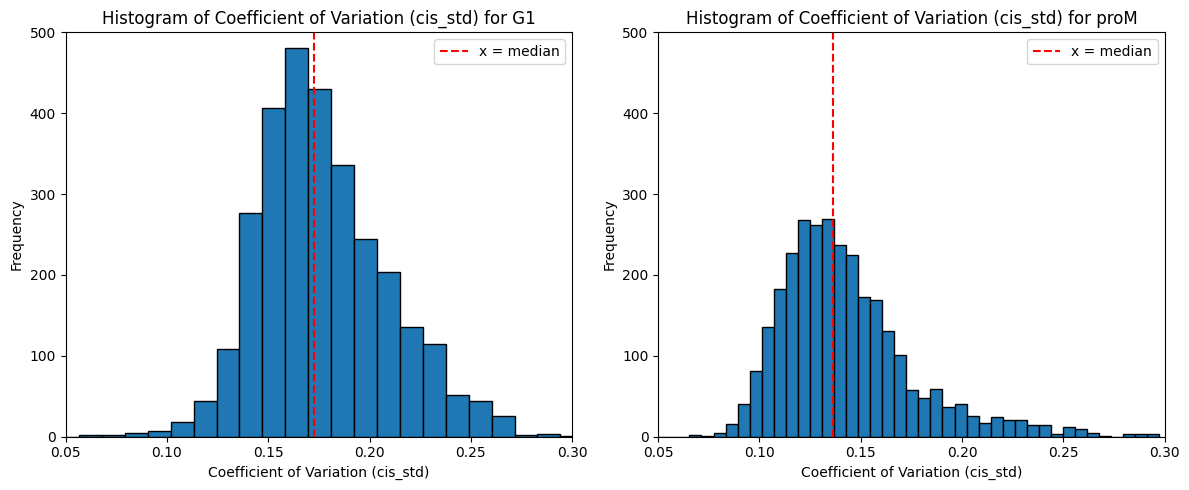

In [40]:
#plot the histgram of G1 and proM
# Calculate means
median_G1 = comp_sum_G1['cis_std'].median()
median_proM = comp_sum_proM['cis_std'].median()


# Create subplots with 1 row and 2 columns
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))  # Adjust the figsize as needed

# Plot histogram for G1
axes[0].hist(comp_sum_G1['cis_std'], bins=50, edgecolor='black')  # Adjust the number of bins as needed
axes[0].set_xlim(0.05, 0.3)
axes[0].set_ylim(0, 500)
axes[0].set_xlabel('Coefficient of Variation (cis_std)')
axes[0].set_ylabel('Frequency')
axes[0].axvline(x=median_G1, color='red', linestyle='--', label='x = median')  # Vertical line at x = mean
axes[0].legend()
axes[0].set_title('Histogram of Coefficient of Variation (cis_std) for G1')

# Plot histogram for proM
axes[1].hist(comp_sum_proM['cis_std'], bins=50, edgecolor='black')  # Adjust the number of bins as needed
axes[1].set_xlim(0.05, 0.3)
axes[1].set_ylim(0, 500)
axes[1].set_xlabel('Coefficient of Variation (cis_std)')
axes[1].set_ylabel('Frequency')
axes[1].axvline(x=median_proM, color='red', linestyle='--', label='x = median')  # Vertical line at x = mean
axes[1].legend()
axes[1].set_title('Histogram of Coefficient of Variation (cis_std) for proM')

# Adjust layout to prevent overlap
plt.tight_layout()

# Save and show the plots
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/benchmark_cistotal_std_histogram>0.3kb.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

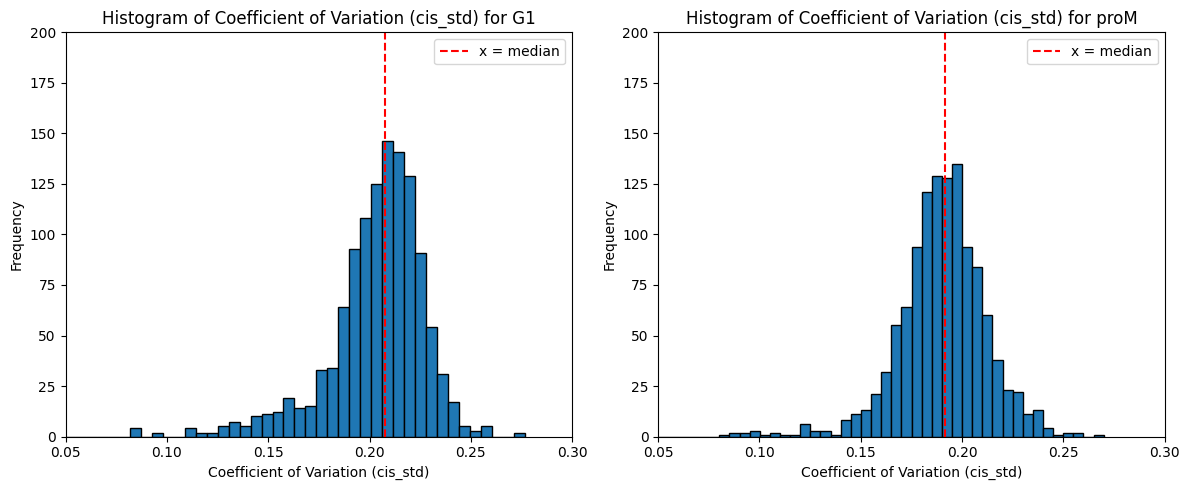

In [6]:
#plot the histgram of G1 and proM
# Calculate means
median_G1 = comp_sum_G1['cis_std'].median()
median_proM = comp_sum_proM['cis_std'].median()


# Create subplots with 1 row and 2 columns
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))  # Adjust the figsize as needed

# Plot histogram for G1
axes[0].hist(comp_sum_G1['cis_std'], bins=50, edgecolor='black')  # Adjust the number of bins as needed
axes[0].set_xlim(0.05, 0.3)
axes[0].set_ylim(0, 200)
axes[0].set_xlabel('Coefficient of Variation (cis_std)')
axes[0].set_ylabel('Frequency')
axes[0].axvline(x=median_G1, color='red', linestyle='--', label='x = median')  # Vertical line at x = mean
axes[0].legend()
axes[0].set_title('Histogram of Coefficient of Variation (cis_std) for G1')

# Plot histogram for proM
axes[1].hist(comp_sum_proM['cis_std'], bins=50, edgecolor='black')  # Adjust the number of bins as needed
axes[1].set_xlim(0.05, 0.3)
axes[1].set_ylim(0, 200)
axes[1].set_xlabel('Coefficient of Variation (cis_std)')
axes[1].set_ylabel('Frequency')
axes[1].axvline(x=median_proM, color='red', linestyle='--', label='x = median')  # Vertical line at x = mean
axes[1].legend()
axes[1].set_title('Histogram of Coefficient of Variation (cis_std) for proM')

# Adjust layout to prevent overlap
plt.tight_layout()

# Save and show the plots
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/benchmark_cistotal_std_histogram>0.3kb.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

In [25]:
#split into chromosomes
comp_sum_G1_split = split_df_by_chrom(comp_sum_G1)
comp_sum_proM_split = split_df_by_chrom(comp_sum_proM)

<Figure size 1200x11250 with 0 Axes>



In [26]:
##check the corelationship between radius and EGV
from scipy.stats import pearsonr
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm

# Set seaborn context to adjust font size
sns.set_context("talk")

fig = plt.figure(figsize=(8, 75), dpi=150)

# Initialize variables
num_chrom = len(chrom_size)

# Set up the subplots
fig, axes = plt.subplots(nrows=num_chrom, ncols=2, figsize=(8, 75), dpi=150)

# Define a normalizer for the color range 0-0.6
norm = mcolors.Normalize(vmin=0.15, vmax=0.5)

# Loop over each DataFrame (G1 and proM)
for idx, (df_split, stage) in enumerate(zip([comp_sum_G1_split, comp_sum_proM_split], ["G1", "proM"])):
    for j, chrom in enumerate(chrom_size):
        # Drop NaN values from the DataFrame
        df = df_split[chrom].dropna()

        # Plot scatter plot with normalized hue
        scatter = sns.scatterplot(
            data=df, x='E1', y='cis_mean', s=15,
            hue='cis_cv', palette='seismic', legend=False, ax=axes[j, idx],
            hue_norm=norm
        )

        # Plot linear regression line
        sns.regplot(data=df, x='E1', y='cis_mean', scatter=False, color='black', line_kws={'linewidth': 1}, ax=axes[j, idx])

        # Set labels, title, and limits
        axes[j, idx].set_xlabel('E1', fontsize=8)
        axes[j, idx].set_ylabel('cis_mean', fontsize=8)
        axes[j, idx].set_title(f'({stage}, Chromosome: {chrom})', fontsize=10)
        axes[j, idx].set_ylim(0.30, 0.9)
        axes[j, idx].set_xlim(-1.05, 1.05)

        # Calculate Pearson correlation coefficient
        corr_coeff = df['E1'].corr(df['cis_mean'])

        # Annotate plot with Pearson correlation coefficient
        axes[j, idx].annotate(f"Pearson Corr: {corr_coeff:.2f}", xy=(0.95, 0.8), xycoords='axes fraction', fontsize=10, ha='right')

        # Add colorbar to each subplot
        sm = cm.ScalarMappable(cmap='seismic', norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=axes[j, idx], orientation='vertical', shrink=0.5, pad=0.02)
        cbar.set_label('cis_cv', fontsize=6)
        cbar.ax.tick_params(labelsize=8)

        # Set font size for x and y tick labels
        axes[j, idx].tick_params(axis='both', which='major', labelsize=8)

# Adjust layout to prevent overlap and save the figure
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/benchmark_cistotal_chromosome.pdf", 
            format="pdf", bbox_inches="tight")

# Show the plot
plt.show()
